# Crime Data Recommendation System

## Data Processing

In [20]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Load data
csv_path = Path("data/chicago_crimes.csv")
if csv_path.exists():
    df = pd.read_csv(csv_path)
else:
    url = "https://data.cityofchicago.org/resource/ijzp-q8t2.csv?$limit=1000000"
    df = pd.read_csv(url)
    csv_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(csv_path, index=False)

# Only include the following crimes
crime_types = [
    "ROBBERY",
    "THEFT",
    "MOTOR VEHICLE THEFT",
    "BURGLARY",
    "CRIMINAL DAMAGE",
    "CRIMINAL TRESPASS",
]
df = df.loc[df["primary_type"].isin(crime_types)].copy()
print(f"Matching crime rows: {len(df):,}")

# Drop un-needed features

Matching crime rows: 516,111


## EDA - Exploratory Data Analysis

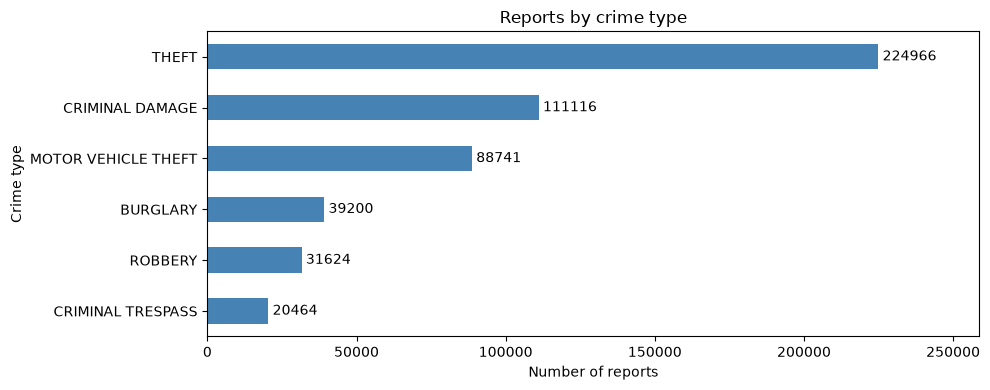

In [21]:
# Distribution of crime types
crime_counts = df["primary_type"].value_counts().sort_values()
ax = crime_counts.plot.barh(figsize=(10, 4), color="steelblue")
ax.set(title="Reports by crime type", xlabel="Number of reports", ylabel="Crime type")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

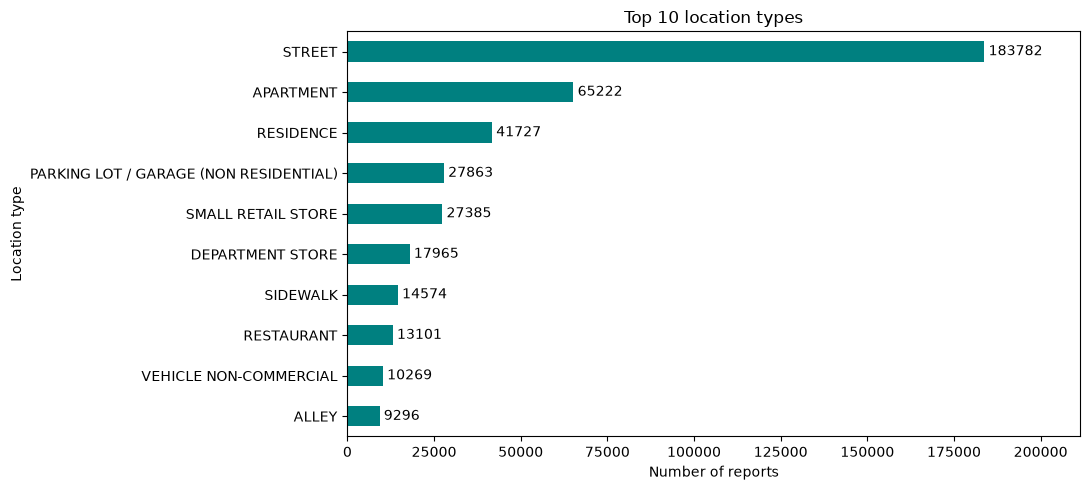

In [22]:
# Distribution of locations
top_locations = df["location_description"].value_counts().head(10).sort_values()
ax = top_locations.plot.barh(figsize=(11, 5), color="teal")
ax.set(title="Top 10 location types", xlabel="Number of reports", ylabel="Location type")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.15)
plt.tight_layout()
plt.show()

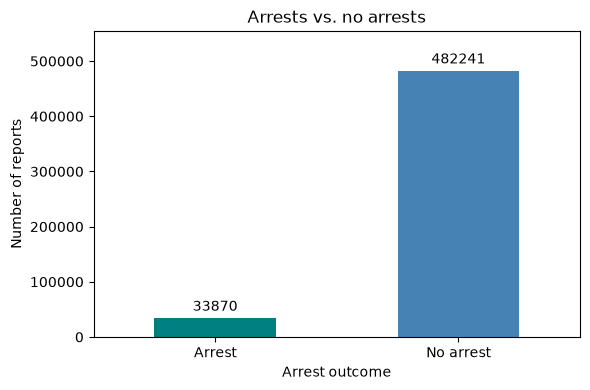

In [23]:
arrest_counts = df["arrest"].value_counts().reindex([True, False], fill_value=0)
arrest_counts.index = ["Arrest", "No arrest"]
ax = arrest_counts.plot.bar(figsize=(6, 4), color=["teal", "steelblue"], rot=0)
ax.set(title="Arrests vs. no arrests", xlabel="Arrest outcome", ylabel="Number of reports")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

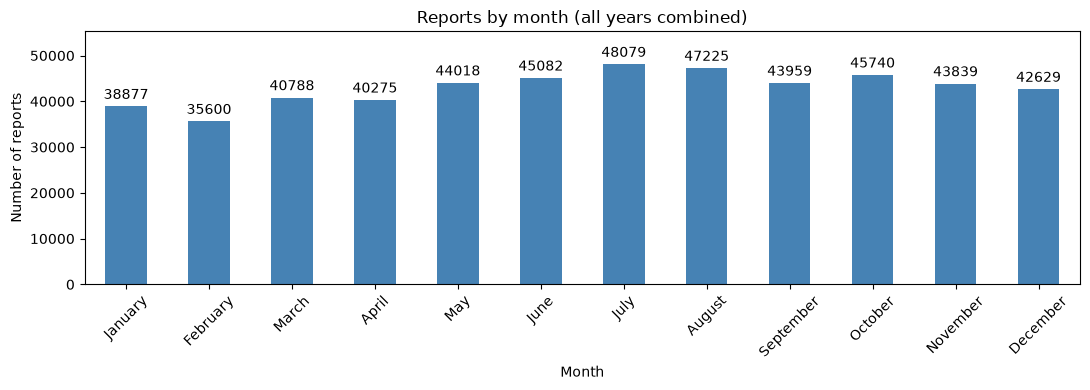

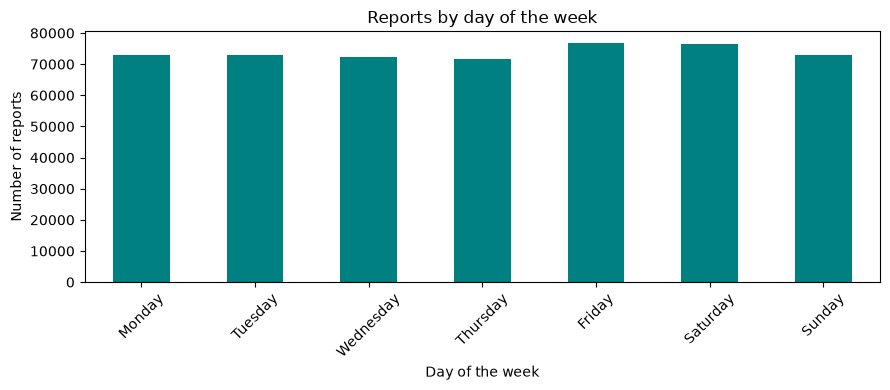

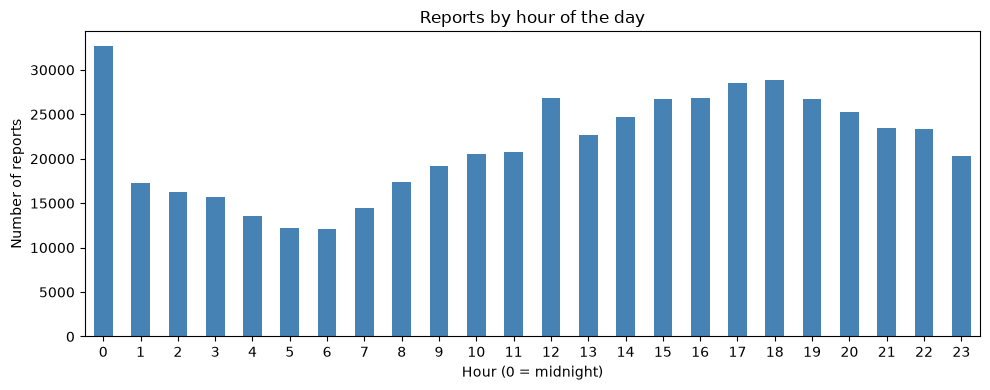

In [24]:
crime_dates = pd.to_datetime(df["date"], errors="coerce")
months = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December",
]
monthly_counts = crime_dates.dt.month_name().value_counts().reindex(months, fill_value=0)

ax = monthly_counts.plot.bar(figsize=(11, 4), color="steelblue", rot=45)
ax.set(title="Reports by month (all years combined)", xlabel="Month", ylabel="Number of reports")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.15)
plt.tight_layout()
plt.show()


weekdays = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_counts = crime_dates.dt.day_name().value_counts().reindex(weekdays, fill_value=0)
ax = weekday_counts.plot.bar(figsize=(9, 4), color="teal", rot=45)
ax.set(title="Reports by day of the week", xlabel="Day of the week", ylabel="Number of reports")
plt.tight_layout()
plt.show()


hourly_counts = crime_dates.dt.hour.value_counts().reindex(range(24), fill_value=0)
ax = hourly_counts.plot.bar(figsize=(10, 4), color="steelblue", rot=0)
ax.set(title="Reports by hour of the day", xlabel="Hour (0 = midnight)", ylabel="Number of reports")
plt.tight_layout()
plt.show()

# Modeling

### Model 1 - Arrest Made (Logistic Regression)

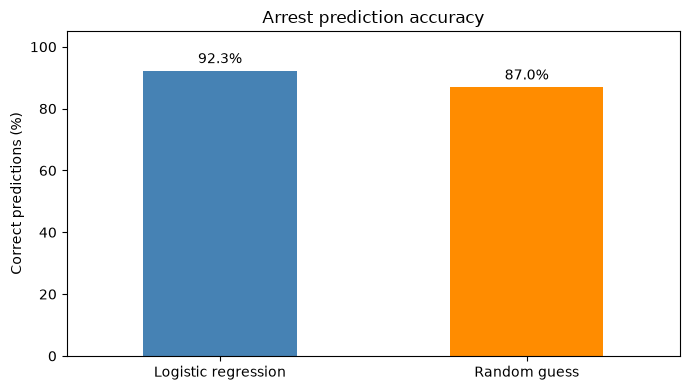

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder

# Use the crime type and location as inputs.
dates = pd.to_datetime(df["date"])
features = df[["primary_type", "location_description", "community_area"]].astype(str)

# Train on the older 80% of reports and test on the newer 20%.
split_date = dates.quantile(0.8)
training_rows = dates < split_date
testing_rows = ~training_rows

# Convert category names into numeric input columns.
encoder = OneHotEncoder(handle_unknown="ignore")
X_train = encoder.fit_transform(features.loc[training_rows])
X_test = encoder.transform(features.loc[testing_rows])

# Use 1 for an arrest and 0 for no arrest.
y_train = df.loc[training_rows, "arrest"].astype(int).to_numpy()
y_test = df.loc[testing_rows, "arrest"].astype(int).to_numpy()

# Fit the model and predict arrests for the test reports.
arrest_model = LogisticRegression(max_iter=1000)
arrest_model.fit(X_train, y_train)
arrest_predictions = arrest_model.predict(X_test)

# Randomly guess "arrest" at the rate seen in the training data.
arrest_rate = y_train.mean()
rng = np.random.default_rng(42)
random_predictions = rng.random(len(y_test)) < arrest_rate

# Compare the percentage of correct predictions.
accuracy = pd.Series({
    "Logistic regression": (arrest_predictions == y_test).mean() * 100,
    "Random guess": (random_predictions == y_test).mean() * 100,
})

ax = accuracy.plot.bar(figsize=(7, 4), rot=0, color=["steelblue", "darkorange"])
ax.set(title="Arrest prediction accuracy", ylabel="Correct predictions (%)", ylim=(0, 105))
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.tight_layout()
plt.show()

### Model 2 - Location 

### Model 3 - Temporal Model (Logistic Regression)

                     MSE    RMSE  Avg Log-Likelihood  Precision@Top5% (%)
Temporal LR       0.0670  0.2589             -0.2519              31.8543
Random guess      0.3348  0.5786             -1.0041               7.4792
Always no arrest  0.0767  0.2769             -2.6477               6.9948


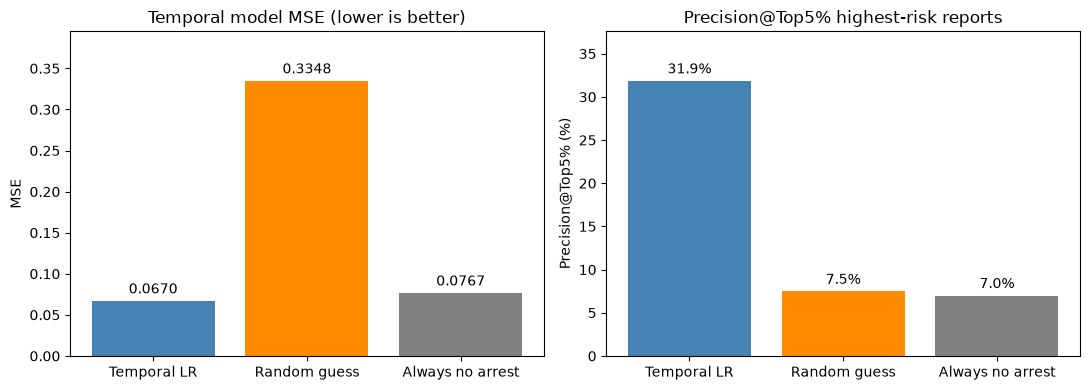

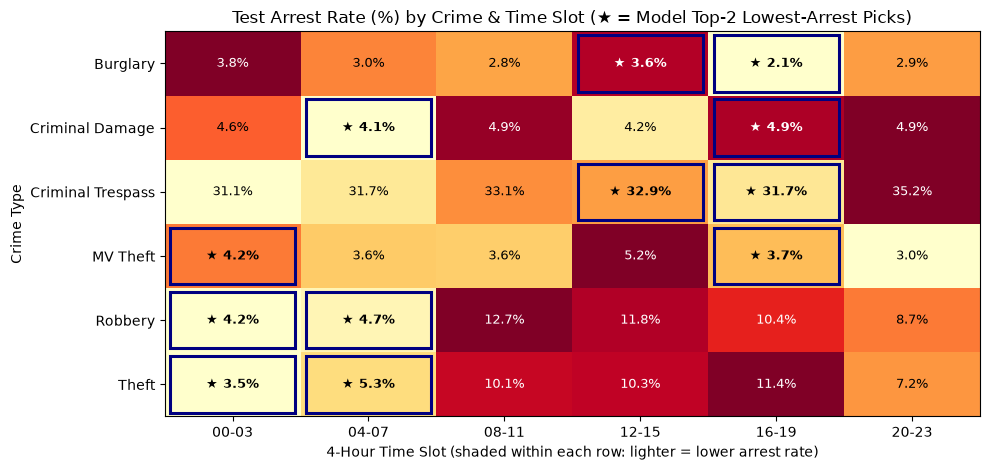

In [ ]:
import matplotlib.patches as patches
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import OneHotEncoder

# Use crime_type x time_slot interaction plus day of week and month as temporal inputs.
dates = pd.to_datetime(df["date"])
time_slots = ["00-03", "04-07", "08-11", "12-15", "16-19", "20-23"]
slot = pd.cut(dates.dt.hour, bins=[-1, 3, 7, 11, 15, 19, 23], labels=time_slots).astype(str)
features = pd.DataFrame({
    "crime_slot": df["primary_type"].astype(str) + "_" + slot,
    "day_of_week": dates.dt.day_name(),
    "month": dates.dt.month.astype(str),
})

# Train 80% | Test 20% (chronological split, Old -> New).
split_date = dates.quantile(0.8)
training_rows = dates < split_date
testing_rows = ~training_rows

# Convert category names into numeric input columns.
encoder = OneHotEncoder(handle_unknown="ignore")
X_train = encoder.fit_transform(features.loc[training_rows])
X_test = encoder.transform(features.loc[testing_rows])

# Arrest: 1, No arrest: 0
y_train = df.loc[training_rows, "arrest"].astype(int).to_numpy()
y_test = df.loc[testing_rows, "arrest"].astype(int).to_numpy()

# Fit the model and predict arrest probabilities
temporal_model = LogisticRegression(max_iter=1000)
temporal_model.fit(X_train, y_train)
temporal_probs = temporal_model.predict_proba(X_test)[:, 1]

# Baselines: random probability scores and always predicting 0 ("no arrest").
rng = np.random.default_rng(42)
random_probs = rng.random(len(y_test))
always_no_arrest = np.zeros(len(y_test), dtype=float)

def avg_log_likelihood(y_true, y_prob):
    p = np.clip(y_prob, 1e-15, 1 - 1e-15)
    return float(np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p)))

def precision_at_top_frac(y_true, y_prob, frac=0.05):
    n = max(1, int(frac * len(y_true)))
    top_idx = np.argsort(y_prob)[-n:]
    return float(y_true[top_idx].mean() * 100)

# Evaluate using MSE, RMSE, Average Log-Likelihood, and Precision@Top5%.
models = {
    "Temporal LR": temporal_probs,
    "Random guess": random_probs,
    "Always no arrest": always_no_arrest,
}
metrics = pd.DataFrame({
    name: {
        "MSE": mean_squared_error(y_test, probs),
        "RMSE": np.sqrt(mean_squared_error(y_test, probs)),
        "Avg Log-Likelihood": avg_log_likelihood(y_test, probs),
        "Precision@Top5% (%)": precision_at_top_frac(y_test, probs, frac=0.05),
    }
    for name, probs in models.items()
}).T
print(metrics.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
bar_colors = ["steelblue", "darkorange", "gray"]

bars_mse = axes[0].bar(metrics.index, metrics["MSE"], color=bar_colors)
axes[0].bar_label(bars_mse, fmt="%.4f", padding=3)
axes[0].set(title="Temporal model MSE (lower is better)", ylabel="MSE", ylim=(0, metrics["MSE"].max() * 1.18))

bars_prec = axes[1].bar(metrics.index, metrics["Precision@Top5% (%)"], color=bar_colors)
axes[1].bar_label(bars_prec, fmt="%.1f%%", padding=3)
axes[1].set(title="Precision@Top5% highest-risk reports", ylabel="Precision@Top5% (%)", ylim=(0, metrics["Precision@Top5% (%)"].max() * 1.18))

plt.tight_layout()
plt.show()

# Visualize actual test arrest rates by crime & time slot, highlighting the model's Top-2 lowest-arrest picks.
test_eval = pd.DataFrame({
    "primary_type": df.loc[testing_rows, "primary_type"].values,
    "time_slot": slot.loc[testing_rows].values,
    "actual_arrest": y_test,
    "pred_prob": temporal_probs,
})
slot_stats = test_eval.groupby(["primary_type", "time_slot"], as_index=False).mean()
actual_grid = slot_stats.pivot(index="primary_type", columns="time_slot", values="actual_arrest")[time_slots] * 100
pred_grid = slot_stats.pivot(index="primary_type", columns="time_slot", values="pred_prob")[time_slots]
norm_grid = actual_grid.sub(actual_grid.min(axis=1), axis=0).div(actual_grid.max(axis=1) - actual_grid.min(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.imshow(norm_grid.values, cmap="YlOrRd", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(time_slots)))
ax.set_xticklabels(time_slots)
ax.set_yticks(range(len(actual_grid.index)))
ax.set_yticklabels([c.title().replace("Motor Vehicle Theft", "MV Theft") for c in actual_grid.index])
ax.set(
    title="Test Arrest Rate (%) by Crime & Time Slot (★ = Model Top-2 Lowest-Arrest Picks)",
    xlabel="4-Hour Time Slot (shaded within each row: lighter = lower arrest rate)",
    ylabel="Crime Type",
)

for r, crime in enumerate(actual_grid.index):
    top2_slots = set(pred_grid.loc[crime].nsmallest(2).index)
    for c, ts in enumerate(time_slots):
        val = actual_grid.loc[crime, ts]
        is_pick = ts in top2_slots
        text_color = "white" if norm_grid.loc[crime, ts] > 0.65 else "black"
        label = f"★ {val:.1f}%" if is_pick else f"{val:.1f}%"
        ax.text(c, r, label, ha="center", va="center", color=text_color, fontweight="bold" if is_pick else "normal", fontsize=9.5)
        if is_pick:
            ax.add_patch(patches.Rectangle((c - 0.46, r - 0.44), 0.92, 0.88, linewidth=2.2, edgecolor="navy", facecolor="none"))

plt.tight_layout()
plt.show()

### Model 4 - Patrol Recommendation (Hybrid Ranking)

Giga model